# minGRU and minLSTM from Scratch (Feng et al., 2024)
Minimal recurrent sequence architectures with parallel prefix scan training.

In [1]:
import math, time, json, random, os

import numpy as np

import pandas as pd

import torch, torch.nn as nn, torch.nn.functional as F

import matplotlib.pyplot as plt

from IPython.display import display



def set_seed(s):

    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)



device = "cuda" if torch.cuda.is_available() else "cpu"

print("device:", device, "| torch:", torch.__version__)



FAST = False      # True: tiny runs to check that every cell works. False: the real runs.

RESULTS = {}

set_seed(0)

device: cuda | torch: 2.11.0+cu130


## 1. Hand Example
4-step numerical example verifying the associative recurrence pair rule: `(a1*a2, a2*b1 + b2)`.

In [2]:
x = np.array([1.0, -0.5, 2.0, 0.5])

sig = lambda v: 1 / (1 + np.exp(-v))



# Forward pass on 4 numbers

z = sig(0.8 * x)

a = 1.0 - z

b = z * (0.9 * x)



# Sequential loop

h_loop = np.zeros(len(x))

h_prev = 0.0

for t in range(len(x)):

    h_prev = a[t] * h_prev + b[t]

    h_loop[t] = h_prev



# Parallel scan using associative pair merge: (a1, b1) o (a2, b2) = (a1*a2, a2*b1 + b2)

combine = lambda p1, p2: (p1[0] * p2[0], p2[0] * p1[1] + p2[1])

p = [(a[t], b[t]) for t in range(len(x))]

p1 = [p[0], combine(p[0], p[1]), combine(p[1], p[2]), combine(p[2], p[3])]

p2 = [p1[0], p1[1], combine(p1[0], p1[2]), combine(p1[1], p1[3])]

h_scan = np.array([pt[1] for pt in p2])



expected = np.array([0.621, 0.191, 1.530, 0.883])

print(np.round(h_loop, 3), np.round(h_scan, 3))

assert np.allclose(h_loop, expected, atol=1e-3) and np.allclose(h_scan, expected, atol=1e-3)


[0.621 0.191 1.53  0.883] [0.621 0.191 1.53  0.883]


## 2. Parallel Scan Primitives
Sequential reference loop, doubling tree scan, and numerically stable Heinsen log-space scan.

In [3]:
def scan_loop(a, b, h0=None):

    """Reference sequential recurrence: h_t = a_t * h_(t-1) + b_t."""

    B, T, D = a.shape

    h = []

    h_prev = h0 if h0 is not None else torch.zeros(B, D, dtype=a.dtype, device=a.device)

    for t in range(T):

        h_prev = a[:, t] * h_prev + b[:, t]

        h.append(h_prev)

    return torch.stack(h, dim=1)



def scan_tree(a, b, h0=None):

    """Doubling parallel prefix scan via associative pair rule."""

    B, T, D = a.shape

    a_cur, b_cur = a, b

    if h0 is not None:

        b_cur = torch.cat([(b[:, :1] + a[:, :1] * h0.unsqueeze(1)), b[:, 1:]], dim=1)

    offset = 1

    while offset < T:

        b_next = torch.cat([b_cur[:, :offset], a_cur[:, offset:] * b_cur[:, :-offset] + b_cur[:, offset:]], dim=1)

        a_next = torch.cat([a_cur[:, :offset], a_cur[:, offset:] * a_cur[:, :-offset]], dim=1)

        a_cur, b_cur = a_next, b_next

        offset *= 2

    return b_cur



def scan_log(log_a, log_b, log_h0=None):

    """Numerically stable log-space scan based on Heinsen (2023)."""

    if log_h0 is None:

        a_star = torch.cumsum(log_a, dim=1)

        log_h = a_star + torch.logcumsumexp(log_b - a_star, dim=1)

        return torch.exp(log_h)

    else:

        log_values = torch.cat([log_h0.unsqueeze(1), log_b], dim=1)

        a_star = F.pad(torch.cumsum(log_a, dim=1), (0, 0, 1, 0))

        log_h = a_star + torch.logcumsumexp(log_values - a_star, dim=1)

        return torch.exp(log_h)[:, 1:]


In [4]:
def test_scans():
    torch.manual_seed(0)
    for T in [1, 2, 7, 64, 257]:
        a = torch.rand(2, T, 3, dtype=torch.float64) * 0.9 + 0.05
        b = torch.rand(2, T, 3, dtype=torch.float64) + 0.01      # positive, so log works
        h0 = torch.rand(2, 3, dtype=torch.float64) + 0.1
        ref, ref0 = scan_loop(a, b), scan_loop(a, b, h0)
        d1 = (scan_tree(a, b) - ref).abs().max().item()
        d2 = (scan_tree(a, b, h0) - ref0).abs().max().item()
        d3 = (scan_log(a.log(), b.log()) - ref).abs().max().item()
        d4 = (scan_log(a.log(), b.log(), h0.log()) - ref0).abs().max().item()
        print(f"T={T:4d}   tree {d1:.1e} {d2:.1e}   log {d3:.1e} {d4:.1e}")
        assert max(d1, d2, d3, d4) < 1e-10
    print("scan tests passed")

test_scans()

T=   1   tree 0.0e+00 0.0e+00   log 2.8e-17 1.1e-16
T=   2   tree 0.0e+00 0.0e+00   log 1.1e-16 2.2e-16
T=   7   tree 2.2e-16 2.2e-16   log 8.9e-16 1.0e-15
T=  64   tree 8.9e-16 6.7e-16   log 1.1e-14 1.1e-14
T= 257   tree 8.9e-16 8.9e-16   log 5.6e-14 5.6e-14
scan tests passed


## 3. minGRU Module
Minimal GRU implementation with input-only gating, supporting sequential and parallel modes.

In [5]:
def g(x):          # paper, Appendix B: keeps the candidate positive

    return torch.where(x >= 0, x + 0.5, torch.sigmoid(x))



def log_g(x):

    return torch.where(x >= 0, (F.relu(x) + 0.5).log(), -F.softplus(-x))



class MinGRU(nn.Module):

    def __init__(self, d_in, d_hidden, use_log=True):

        super().__init__()

        self.use_log = use_log

        self.linear_z = nn.Linear(d_in, d_hidden)

        self.linear_h = nn.Linear(d_in, d_hidden)



    def forward(self, x, h0=None, parallel=True, return_gates=False):

        if self.use_log:

            k = self.linear_z(x)

            cand_raw = self.linear_h(x)

            if parallel:

                log_coeffs = -F.softplus(k)

                log_z = -F.softplus(-k)

                log_b = log_z + log_g(cand_raw)

                log_h0 = h0.log() if h0 is not None else None

                h = scan_log(log_coeffs, log_b, log_h0)

            else:

                z = torch.sigmoid(k)

                h = scan_loop(1.0 - z, z * g(cand_raw), h0)

            return (h, {"z": torch.sigmoid(k), "cand": g(cand_raw)}) if return_gates else h

        else:

            z = torch.sigmoid(self.linear_z(x))

            cand = self.linear_h(x)

            a, b = 1.0 - z, z * cand

            h = scan_tree(a, b, h0) if parallel else scan_loop(a, b, h0)

            return (h, {"z": z, "cand": cand}) if return_gates else h


In [6]:
def run_minrnn_tests(cls, name):
    torch.manual_seed(0)
    for use_log in [False, True]:
        for with_h0 in [False, True]:
            m = cls(5, 8, use_log=use_log).double()
            x = torch.randn(3, 33, 5, dtype=torch.float64)
            h0 = (torch.rand(3, 8, dtype=torch.float64) + 0.1) if with_h0 else None
            h_seq = m(x, h0=h0, parallel=False)
            h_par = m(x, h0=h0, parallel=True)
            d_out = (h_seq - h_par).abs().max().item()
            m.zero_grad(); h_seq.pow(2).sum().backward()
            g_seq = [p.grad.clone() for p in m.parameters()]
            m.zero_grad(); m(x, h0=h0, parallel=True).pow(2).sum().backward()
            g_par = [p.grad.clone() for p in m.parameters()]
            d_grad = max((u - v).abs().max().item() for u, v in zip(g_seq, g_par))
            print(f"{name}  use_log={use_log!s:5}  h0={with_h0!s:5}   output diff {d_out:.1e}   grad diff {d_grad:.1e}")
            assert d_out < 1e-8 and d_grad < 1e-8
    # causality: changing the future must not change the past
    m = cls(5, 8).double()
    x = torch.randn(2, 20, 5, dtype=torch.float64)
    x2 = x.clone(); x2[:, 12:] += 1.0
    assert (m(x) - m(x2))[:, :12].abs().max().item() < 1e-12
    # bounded state (h0 = 0): |h_t| <= max |candidate|
    m = cls(5, 8, use_log=False).double()
    h, aux = m(x, return_gates=True)
    assert h.abs().max().item() <= aux["cand"].abs().max().item() + 1e-9
    print(name, "all tests passed")

run_minrnn_tests(MinGRU, "MinGRU")

MinGRU  use_log=False  h0=False   output diff 2.2e-16   grad diff 1.4e-14
MinGRU  use_log=False  h0=True    output diff 2.2e-16   grad diff 1.4e-14
MinGRU  use_log=True   h0=False   output diff 3.3e-15   grad diff 1.8e-12
MinGRU  use_log=True   h0=True    output diff 5.6e-15   grad diff 1.4e-12
MinGRU all tests passed


## 4. minLSTM Module
Minimal LSTM implementation with normalized gates `f' + i' = 1` in sequential and parallel modes.

In [7]:
class MinLSTM(nn.Module):

    def __init__(self, d_in, d_hidden, use_log=True):

        super().__init__()

        self.use_log = use_log

        self.linear_f = nn.Linear(d_in, d_hidden)

        self.linear_i = nn.Linear(d_in, d_hidden)

        self.linear_h = nn.Linear(d_in, d_hidden)



    def forward(self, x, h0=None, parallel=True, return_gates=False):

        if self.use_log:

            p_f = self.linear_f(x)

            p_i = self.linear_i(x)

            cand_raw = self.linear_h(x)

            if parallel:

                diff = F.softplus(-p_f) - F.softplus(-p_i)

                log_f = -F.softplus(diff)

                log_i = -F.softplus(-diff)

                log_b = log_i + log_g(cand_raw)

                log_h0 = h0.log() if h0 is not None else None

                h = scan_log(log_f, log_b, log_h0)

            else:

                f, i = torch.sigmoid(p_f), torch.sigmoid(p_i)

                f_prime, i_prime = f / (f + i), i / (f + i)

                h = scan_loop(f_prime, i_prime * g(cand_raw), h0)

            if return_gates:

                f, i = torch.sigmoid(p_f), torch.sigmoid(p_i)

                return h, {"f": f / (f + i), "i": i / (f + i), "cand": g(cand_raw)}

            return h

        else:

            f, i = torch.sigmoid(self.linear_f(x)), torch.sigmoid(self.linear_i(x))

            f_prime, i_prime = f / (f + i), i / (f + i)

            cand = self.linear_h(x)

            h = scan_tree(f_prime, i_prime * cand, h0) if parallel else scan_loop(f_prime, i_prime * cand, h0)

            return (h, {"f": f_prime, "i": i_prime, "cand": cand}) if return_gates else h


In [8]:
run_minrnn_tests(MinLSTM, "MinLSTM")

MinLSTM  use_log=False  h0=False   output diff 2.2e-16   grad diff 1.4e-14
MinLSTM  use_log=False  h0=True    output diff 2.2e-16   grad diff 7.1e-15
MinLSTM  use_log=True   h0=False   output diff 4.2e-15   grad diff 6.2e-13
MinLSTM  use_log=True   h0=True    output diff 4.4e-15   grad diff 5.5e-13
MinLSTM all tests passed


## 5. Parameter Count Verification
Parameter efficiency comparison against standard GRU and LSTM across hidden expansion ratios.

In [9]:
def count_params(m):
    return sum(p.numel() for p in m.parameters())

d_x = 64
rows = []
for alpha in [1, 2, 3, 4]:
    d_h = alpha * d_x
    w_mingru  = sum(p.numel() for n, p in MinGRU(d_x, d_h).named_parameters() if "weight" in n)
    w_minlstm = sum(p.numel() for n, p in MinLSTM(d_x, d_h).named_parameters() if "weight" in n)
    gru, lstm = 3 * d_h * (d_x + d_h), 4 * d_h * (d_x + d_h)
    rows.append(dict(alpha=alpha, minGRU_vs_GRU=f"{w_mingru / gru:.0%}", minLSTM_vs_LSTM=f"{w_minlstm / lstm:.0%}"))
display(pd.DataFrame(rows))
# paper: minGRU 33/22/17/13 %, minLSTM 38/25/19/15 %
RESULTS["params"] = rows

,alpha,minGRU_vs_GRU,minLSTM_vs_LSTM
0,1,33%,38%
1,2,22%,25%
2,3,17%,19%
3,4,13%,15%


## 6. Blocks and Baseline Models
Causal Conv4, LayerNorm, and down-projection wrappers alongside GRU, LSTM, and Transformer baselines.

In [10]:
class MLP(nn.Module):

    def __init__(self, d, dropout=0.0):

        super().__init__()

        self.net = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d), nn.Dropout(dropout))

    def forward(self, x):

        return self.net(x)



class MinRNNBlock(nn.Module):

    """x -> x + DownProj(minRNN(Conv4?(Norm(x))))   then optionally   x -> x + MLP(Norm(x))"""

    def __init__(self, d, kind="gru", expansion=2, conv=False, mlp=False, dropout=0.0, use_log=True):

        super().__init__()

        self.norm = nn.LayerNorm(d)

        self.conv = nn.Conv1d(d, d, kernel_size=4, groups=d) if conv else None

        rnn_cls = MinGRU if kind == "gru" else MinLSTM

        self.rnn = rnn_cls(d, expansion * d, use_log=use_log)

        self.proj = nn.Linear(expansion * d, d)

        self.drop = nn.Dropout(dropout)

        self.mlp_norm = nn.LayerNorm(d) if mlp else None

        self.mlp = MLP(d, dropout) if mlp else None



    def forward(self, x, return_gates=False):

        h = self.norm(x)

        if self.conv is not None:

            h = self.conv(F.pad(h.transpose(1, 2), (3, 0))).transpose(1, 2)

        gates = None

        if return_gates:

            y, gates = self.rnn(h, return_gates=True)

        else:

            y = self.rnn(h)

        x = x + self.drop(self.proj(y))

        if self.mlp is not None:

            x = x + self.mlp(self.mlp_norm(x))

        return (x, gates) if return_gates else x



class PlainRNNBlock(nn.Module):

    """Original GRU or LSTM written as a Python loop over time (gates DO read h(t-1)).

    Same wrapper as CudnnBlock: Norm -> recurrent layer -> residual (-> optional MLP)."""

    def __init__(self, d, kind="gru", dropout=0.0, mlp=False):

        super().__init__()

        self.norm = nn.LayerNorm(d)

        self.kind = kind

        self.cell = nn.GRUCell(d, d) if kind == "gru" else nn.LSTMCell(d, d)

        self.drop = nn.Dropout(dropout)

        self.mlp_norm, self.mlp = (nn.LayerNorm(d), MLP(d, dropout)) if mlp else (None, None)



    def forward(self, x):

        h = self.norm(x)

        B, T, D = h.shape

        states = []

        if self.kind == "gru":

            s = torch.zeros(B, D, device=x.device, dtype=x.dtype)

            for t in range(T):

                s = self.cell(h[:, t], s)

                states.append(s)

        else:

            hx = torch.zeros(B, D, device=x.device, dtype=x.dtype)

            cx = torch.zeros(B, D, device=x.device, dtype=x.dtype)

            for t in range(T):

                hx, cx = self.cell(h[:, t], (hx, cx))

                states.append(hx)

        y = torch.stack(states, dim=1)

        x = x + self.drop(y)

        return x + self.mlp(self.mlp_norm(x)) if self.mlp is not None else x



class CudnnBlock(nn.Module):

    """Built-in cuDNN GRU/LSTM with the same residual + norm wrapper (for accuracy comparisons)."""

    def __init__(self, d, kind="gru", dropout=0.0, mlp=False):

        super().__init__()

        self.norm = nn.LayerNorm(d)

        self.rnn = (nn.GRU if kind == "gru" else nn.LSTM)(d, d, batch_first=True)

        self.drop = nn.Dropout(dropout)

        self.mlp_norm, self.mlp = (nn.LayerNorm(d), MLP(d, dropout)) if mlp else (None, None)

    def forward(self, x):

        y, _ = self.rnn(self.norm(x))

        x = x + self.drop(y)

        return x + self.mlp(self.mlp_norm(x)) if self.mlp is not None else x



class TransformerBlock(nn.Module):

    def __init__(self, d, n_heads=6, dropout=0.0):

        super().__init__()

        self.h = n_heads

        self.n1, self.qkv, self.proj = nn.LayerNorm(d), nn.Linear(d, 3 * d), nn.Linear(d, d)

        self.n2, self.mlp, self.drop = nn.LayerNorm(d), MLP(d, dropout), nn.Dropout(dropout)

    def forward(self, x):

        B, T, D = x.shape

        q, k, v = self.qkv(self.n1(x)).split(D, dim=2)

        q, k, v = (t.view(B, T, self.h, D // self.h).transpose(1, 2) for t in (q, k, v))

        y = F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B, T, D)

        x = x + self.drop(self.proj(y))

        return x + self.mlp(self.n2(x))



class SeqModel(nn.Module):

    """Embedding -> N blocks -> LayerNorm -> linear head. Returns logits (B, T, vocab)."""

    def __init__(self, vocab, d, n_layers, make_block, max_len=None, pos_emb=False):

        super().__init__()

        self.emb = nn.Embedding(vocab, d)

        self.pos = nn.Embedding(max_len, d) if pos_emb else None

        self.blocks = nn.ModuleList([make_block() for _ in range(n_layers)])

        self.norm, self.head = nn.LayerNorm(d), nn.Linear(d, vocab)

    def forward(self, idx):

        x = self.emb(idx)

        if self.pos is not None:

            x = x + self.pos(torch.arange(idx.size(1), device=idx.device))

        for blk in self.blocks:

            x = blk(x)

        return self.head(self.norm(x))



def build_model(name, vocab, d, n_layers, task="copy", dropout=0.0, max_len=None):

    lm = (task == "lm")      # language modelling adds Conv4 and an MLP sub-block (paper, Appendix C.2)

    pos = False

    if name in ("mingru", "minlstm"):

        mk = lambda: MinRNNBlock(d, kind=name[3:], expansion=2 if lm else 6, conv=lm, mlp=lm, dropout=dropout)

    elif name in ("gru", "lstm"):

        mk = lambda: CudnnBlock(d, kind=name, dropout=dropout, mlp=lm)

    elif name in ("plain_gru", "plain_lstm"):

        mk = lambda: PlainRNNBlock(d, kind=name[6:], dropout=dropout, mlp=lm)

    elif name == "transformer":

        mk = lambda: TransformerBlock(d, n_heads=6 if d % 6 == 0 else 4, dropout=dropout)

        pos = True

    else:

        raise ValueError(name)

    return SeqModel(vocab, d, n_layers, mk, max_len=max_len, pos_emb=pos)



for n in ["mingru", "minlstm", "gru", "lstm", "plain_gru", "plain_lstm", "transformer"]:

    m = build_model(n, 16, 64, 3, max_len=128)

    print(n, count_params(m), m(torch.randint(0, 16, (2, 128))).shape)


mingru 226256 torch.Size([2, 128, 16])
minlstm 301136 torch.Size([2, 128, 16])
gru 77456 torch.Size([2, 128, 16])
lstm 102416 torch.Size([2, 128, 16])
plain_gru 77456 torch.Size([2, 128, 16])
plain_lstm 102416 torch.Size([2, 128, 16])
transformer 160336 torch.Size([2, 128, 16])


## 7. Experiment 1: Selective Copying
Synthetic retrieval task testing information retention across noise tokens and model depths.

In [11]:
def make_batch(B, L, n_data=16, V=16, device=device, gen=None):

    x = torch.zeros(B, L, dtype=torch.long, device=device)

    y = torch.full((B, L), -100, dtype=torch.long, device=device)

    pos = torch.rand(B, L - n_data, device=device, generator=gen).argsort(1)[:, :n_data].sort(1).values

    vals = torch.randint(2, V, (B, n_data), device=device, generator=gen)

    x.scatter_(1, pos, vals)

    x[:, L - n_data:] = 1

    y[:, L - n_data:] = vals

    return x, y



@torch.no_grad()

def eval_copy(model, X, Y, bs=128):

    model.eval(); correct = total = exact = n = 0

    for i in range(0, len(X), bs):

        x, y = X[i:i + bs].to(device), Y[i:i + bs].to(device)

        pred = model(x).argmax(-1); mask = y != -100

        correct += ((pred == y) & mask).sum().item(); total += mask.sum().item()

        exact += (((pred == y) | ~mask).all(1)).sum().item(); n += x.size(0)

    model.train()

    return {"acc": correct / total, "exact": exact / n}



def train(model, batch_fn, eval_fn, steps, lr, eval_every, clip, wd=0.0):

    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)

    hist, run, cnt = [], 0.0, 0

    for step in range(1, steps + 1):

        x, y = batch_fn("train")

        logits = model(x)

        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), ignore_index=-100)

        opt.zero_grad(set_to_none=True); loss.backward()

        nn.utils.clip_grad_norm_(model.parameters(), clip); opt.step()

        run += loss.item(); cnt += 1

        if step % eval_every == 0 or step == steps:

            hist.append({"step": step, "train_loss": run / cnt, **eval_fn(model)}); run, cnt = 0.0, 0

    return hist



# Fast mode: 300 steps test. Real mode: 5000 steps with 3 seeds for reliable mean and std.

SC = dict(L=64, n_data=8, V=16, d=64, bs=64, steps=300, lr=3e-4, seeds=[0]) if FAST else      dict(L=256, n_data=16, V=16, d=64, bs=64, steps=5000, lr=3e-4, seeds=[0, 1, 2])

g_eval = torch.Generator().manual_seed(1234)

EVAL_X, EVAL_Y = make_batch(512, SC["L"], SC["n_data"], SC["V"], device="cpu", gen=g_eval)

print("Selective Copy config:", SC)


Selective Copy config: {'L': 256, 'n_data': 16, 'V': 16, 'd': 64, 'bs': 64, 'steps': 5000, 'lr': 0.0003, 'seeds': [0, 1, 2]}


In [12]:
SC_MODELS = ["mingru", "minlstm", "gru", "lstm","transformer"]
rows, sc_hist = [], {}
for name in SC_MODELS:
    for layers in [1, 2, 3]:
        for seed in SC["seeds"]:
            set_seed(seed)
            model = build_model(name, SC["V"], SC["d"], layers, task="copy", dropout=0.1, max_len=SC["L"]).to(device)
            hist = train(model,
                         batch_fn=lambda split: make_batch(SC["bs"], SC["L"], SC["n_data"], SC["V"]),
                         eval_fn=lambda m: eval_copy(m, EVAL_X, EVAL_Y),
                         steps=SC["steps"], lr=SC["lr"], eval_every=max(SC["steps"] // 10, 1), clip=1.0)
            sc_hist[(name, layers, seed)] = hist
            rows.append(dict(model=name, layers=layers, seed=seed, best_acc=max(h["acc"] for h in hist),
                             final_acc=hist[-1]["acc"], params=count_params(model)))
            print(rows[-1])
df_sc = pd.DataFrame(rows)
RESULTS["copy"] = df_sc.to_dict("records")

{'model': 'mingru', 'layers': 1, 'seed': 0, 'best_acc': 0.259765625, 'final_acc': 0.259765625, 'params': 76880}
{'model': 'mingru', 'layers': 1, 'seed': 1, 'best_acc': 0.26025390625, 'final_acc': 0.2574462890625, 'params': 76880}
{'model': 'mingru', 'layers': 1, 'seed': 2, 'best_acc': 0.2613525390625, 'final_acc': 0.2613525390625, 'params': 76880}
{'model': 'mingru', 'layers': 2, 'seed': 0, 'best_acc': 0.388671875, 'final_acc': 0.388671875, 'params': 151568}
{'model': 'mingru', 'layers': 2, 'seed': 1, 'best_acc': 0.4144287109375, 'final_acc': 0.4144287109375, 'params': 151568}
{'model': 'mingru', 'layers': 2, 'seed': 2, 'best_acc': 0.3953857421875, 'final_acc': 0.3953857421875, 'params': 151568}
{'model': 'mingru', 'layers': 3, 'seed': 0, 'best_acc': 0.4495849609375, 'final_acc': 0.4495849609375, 'params': 226256}
{'model': 'mingru', 'layers': 3, 'seed': 1, 'best_acc': 0.4451904296875, 'final_acc': 0.4451904296875, 'params': 226256}
{'model': 'mingru', 'layers': 3, 'seed': 2, 'best_acc

In [13]:
summary = df_sc.groupby(["model", "layers"]).best_acc.agg(["mean", "std"]).mul(100).round(1).fillna(0.0)

display(summary)


mean  std
model       layers           
gru         1       18.1  0.6
            2       31.4  4.2
            3       42.0  0.9
lstm        1        7.7  0.4
            2        7.5  0.1
            3        7.4  0.0
mingru      1       26.0  0.1
            2       39.9  1.3
            3       45.7  1.6
minlstm     1       25.9  0.2
            2       42.9  3.6
            3       36.2  7.0
transformer 1       40.7  1.0
            2       98.1  0.5
            3       99.9  0.0

## 8. Experiment 2: TinyShakespeare Language Modeling
Character-level language modeling validation loss curves across minRNNs and Transformer.

In [14]:
import urllib.request

url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

if not os.path.exists("input.txt"):

    urllib.request.urlretrieve(url, "input.txt")

text = open("input.txt").read()

chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}

data = torch.tensor([stoi[c] for c in text], dtype=torch.long)

n_split = int(0.9 * len(data)); train_data, val_data = data[:n_split], data[n_split:]

V_LM = len(chars)

print("characters:", len(text), "| vocab:", V_LM)



def lm_batch(split, bs, block):

    d = train_data if split == "train" else val_data

    ix = torch.randint(len(d) - block - 1, (bs,))

    x = torch.stack([d[i:i + block] for i in ix]); y = torch.stack([d[i + 1:i + block + 1] for i in ix])

    return x.to(device), y.to(device)



@torch.no_grad()

def eval_lm(model, block, bs=32, iters=20):

    model.eval(); losses = []

    for _ in range(iters):

        x, y = lm_batch("val", bs, block)

        logits = model(x)

        losses.append(F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1)).item())

    model.train()

    return {"val_loss": float(np.mean(losses))}



LM = dict(block=64, bs=32, d=128, layers=2, steps=100, lr=1e-3, dropout=0.2, clip=0.25, eval_every=25) if FAST else      dict(block=256, bs=64, d=384, layers=3, steps=4000, lr=1e-3, dropout=0.2, clip=0.25, eval_every=50)

print("Language modeling config:", LM)


characters: 1115394 | vocab: 65
Language modeling config: {'block': 256, 'bs': 64, 'd': 384, 'layers': 3, 'steps': 4000, 'lr': 0.001, 'dropout': 0.2, 'clip': 0.25, 'eval_every': 50}


Saved Shakespeare minGRU model checkpoint to app/assets/mingru_lm_demo.pt
mingru {'best_val': 1.4951743185520172, 'best_step': 700, 'params': 6265793}
minlstm {'best_val': 1.5092190265655518, 'best_step': 700, 'params': 7152833}
gru {'best_val': 1.4617809712886811, 'best_step': 800, 'params': 6261185}
lstm {'best_val': 1.464708924293518, 'best_step': 650, 'params': 7148225}
transformer {'best_val': 1.49350563287735, 'best_step': 1600, 'params': 5472449}


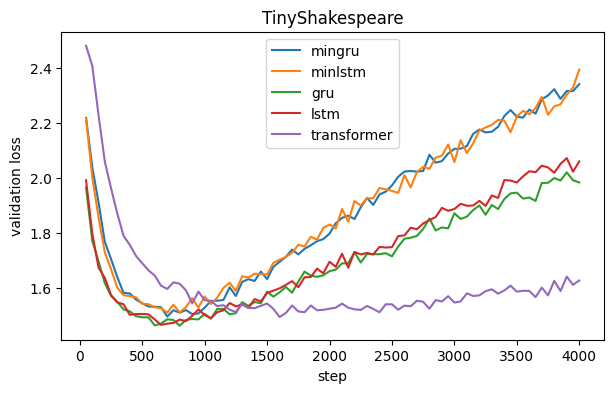

In [15]:
LM_MODELS = ["mingru", "minlstm", "gru", "lstm", "transformer"]

lm_hist = {}

RESULTS["lm"] = {}

for name in LM_MODELS:

    set_seed(0)

    model = build_model(name, V_LM, LM["d"], LM["layers"], task="lm", dropout=LM["dropout"], max_len=LM["block"]).to(device)

    lm_hist[name] = train(model,

                          batch_fn=lambda split: lm_batch(split, LM["bs"], LM["block"]),

                          eval_fn=lambda m: eval_lm(m, LM["block"]),

                          steps=LM["steps"], lr=LM["lr"], eval_every=LM["eval_every"], clip=LM["clip"], wd=0.01)

    best = min(lm_hist[name], key=lambda r: r["val_loss"])

    RESULTS["lm"][name] = dict(best_val=best["val_loss"], best_step=best["step"], params=count_params(model))

    if name == "mingru":

        os.makedirs("app/assets", exist_ok=True)

        torch.save(model.state_dict(), "app/assets/mingru_lm_demo.pt")

        print("Saved Shakespeare minGRU model checkpoint to app/assets/mingru_lm_demo.pt")

    print(name, RESULTS["lm"][name])



plt.figure(figsize=(7, 4))

for name, h in lm_hist.items():

    plt.plot([r["step"] for r in h], [r["val_loss"] for r in h], label=name)

plt.xlabel("step"); plt.ylabel("validation loss"); plt.legend(); plt.title("TinyShakespeare"); plt.show()

RESULTS["lm_curves"] = {k: v for k, v in lm_hist.items()}


## 9. Speed and Memory Benchmarking
Latency per training step and peak memory scaling across sequence lengths up to 4096.

In [16]:
def bench_one(name, L, batch=64, d=128, layers=3, V=16, n_warmup=2, n_runs=5):
    model = None
    try:
        model = build_model(name, V, d, layers, task="copy", max_len=L).to(device)
        x = torch.randint(0, V, (batch, L), device=device); y = torch.randint(0, V, (batch, L), device=device)
        def step():
            model.zero_grad(set_to_none=True)
            F.cross_entropy(model(x).reshape(-1, V), y.reshape(-1)).backward()
        if device == "cuda": torch.cuda.reset_peak_memory_stats()
        for _ in range(n_warmup): step()
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n_runs): step()
        if device == "cuda": torch.cuda.synchronize()
        sec = (time.perf_counter() - t0) / n_runs
        mem = torch.cuda.max_memory_allocated() / 2**30 if device == "cuda" else float("nan")
        return sec, mem
    except RuntimeError as e:                      # out of memory and similar
        print("  skipped:", name, L, str(e)[:60])
        return float("nan"), float("nan")
    finally:
        del model
        if device == "cuda": torch.cuda.empty_cache()

BENCH_MODELS = ["plain_gru", "plain_lstm", "mingru", "minlstm", "gru", "lstm", "transformer"]
BENCH_LENGTHS = [64, 128, 256] if FAST else [128, 256, 512, 1024, 2048, 4096]
BENCH_BATCH = 8 if FAST else 64

{'model': 'plain_gru', 'L': 128, 'ms': 202.4633728000481, 'mem_gb': 0.23836469650268555}
{'model': 'plain_gru', 'L': 256, 'ms': 294.5871325999178, 'mem_gb': 0.41452741622924805}
{'model': 'plain_gru', 'L': 512, 'ms': 687.5675260002026, 'mem_gb': 0.767829418182373}
{'model': 'plain_gru', 'L': 1024, 'ms': 2256.975642999896, 'mem_gb': 1.474433422088623}
{'model': 'plain_gru', 'L': 2048, 'ms': 8051.068251000107, 'mem_gb': 2.8881139755249023}
{'model': 'plain_gru', 'L': 4096, 'ms': 29670.623118599906, 'mem_gb': 5.714285850524902}
{'model': 'plain_lstm', 'L': 128, 'ms': 151.51990939993993, 'mem_gb': 0.26226282119750977}
{'model': 'plain_lstm', 'L': 256, 'ms': 322.46635619994777, 'mem_gb': 0.46186304092407227}
{'model': 'plain_lstm', 'L': 512, 'ms': 695.6490307999047, 'mem_gb': 0.8620400428771973}
{'model': 'plain_lstm', 'L': 1024, 'ms': 2278.3768659999623, 'mem_gb': 1.6623940467834473}
{'model': 'plain_lstm', 'L': 2048, 'ms': 8058.281642599832, 'mem_gb': 3.2635746002197266}
{'model': 'plain_

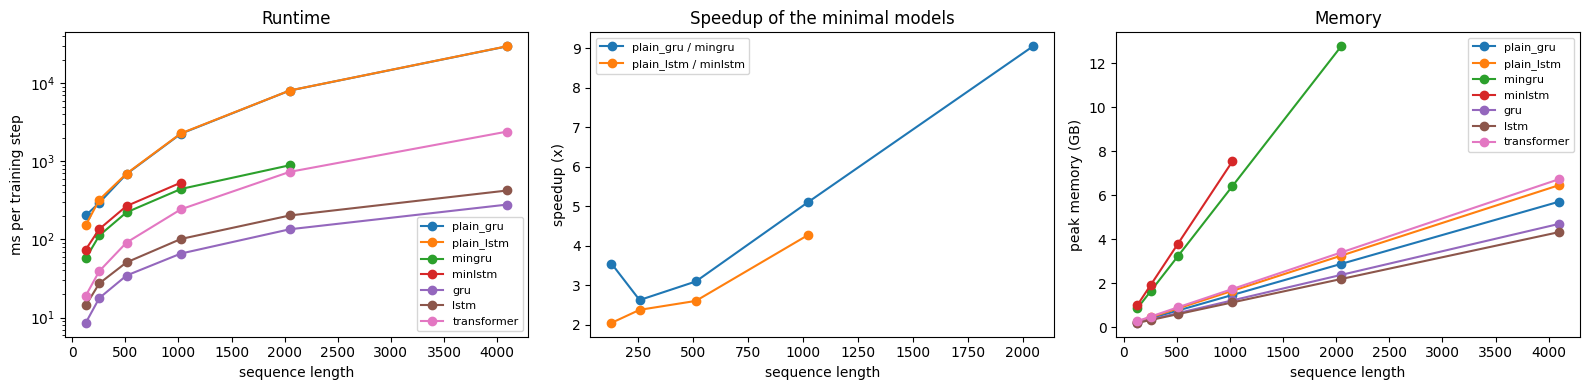

In [17]:
bench = []
for name in BENCH_MODELS:
    for L in BENCH_LENGTHS:
        sec, mem = bench_one(name, L, batch=BENCH_BATCH)
        bench.append(dict(model=name, L=L, ms=sec * 1000, mem_gb=mem)); print(bench[-1])
df_bench = pd.DataFrame(bench)
RESULTS["bench"] = df_bench.to_dict("records")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for name in BENCH_MODELS:
    d_ = df_bench[df_bench.model == name]
    ax[0].plot(d_.L, d_.ms, marker="o", label=name); ax[2].plot(d_.L, d_.mem_gb, marker="o", label=name)
ax[0].set(xlabel="sequence length", ylabel="ms per training step", title="Runtime"); ax[0].set_yscale("log")
for slow, fast in [("plain_gru", "mingru"), ("plain_lstm", "minlstm")]:
    s = df_bench[df_bench.model == slow].set_index("L").ms; f = df_bench[df_bench.model == fast].set_index("L").ms
    ax[1].plot((s / f).index, (s / f).values, marker="o", label=f"{slow} / {fast}")
ax[1].set(xlabel="sequence length", ylabel="speedup (x)", title="Speedup of the minimal models")
ax[2].set(xlabel="sequence length", ylabel="peak memory (GB)", title="Memory")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 10. Ablation Studies
Evaluating depth scaling, forget-gate bias initialization (+3), and candidate activation choices.

In [18]:
# A and B: Depth and gate comparisons from Selective Copy

pivot = df_sc.groupby(["model", "layers"]).best_acc.mean().unstack("layers").mul(100).round(1)

display(pivot)



# C: Forget-gate bias initialization (+3 vs default 0)

def init_forget_bias(model, val=3.0):

    for blk in model.blocks:

        if hasattr(blk, "rnn") and hasattr(blk.rnn, "linear_f") and blk.rnn.linear_f.bias is not None:

            nn.init.constant_(blk.rnn.linear_f.bias, val)

    return model



m_biased = build_model("minlstm", SC["V"], SC["d"], 2).to(device)

init_forget_bias(m_biased, 3.0)

hist_biased = train(m_biased, lambda split: make_batch(SC["bs"], SC["L"], SC["n_data"], SC["V"]),

                    lambda m: eval_copy(m, EVAL_X, EVAL_Y),

                    steps=SC["steps"], lr=SC["lr"], eval_every=max(1, SC["steps"] // 5), clip=1.0)

print("minLSTM (forget bias +3) best acc:", max(r["acc"] for r in hist_biased))



# D: Candidate activation ablation (g(x) vs linear candidate)

m_linear = SeqModel(SC["V"], SC["d"], 2, lambda: MinRNNBlock(SC["d"], kind="gru", expansion=6, use_log=False)).to(device)

hist_linear = train(m_linear, lambda split: make_batch(SC["bs"], SC["L"], SC["n_data"], SC["V"]),

                    lambda m: eval_copy(m, EVAL_X, EVAL_Y),

                    steps=SC["steps"], lr=SC["lr"], eval_every=max(1, SC["steps"] // 5), clip=1.0)

print("minGRU (linear candidate) best acc:", max(r["acc"] for r in hist_linear))


layers,1,2,3
model,,,
gru,18.1,31.4,42.0
lstm,7.7,7.5,7.4
mingru,26.0,39.9,45.7
minlstm,25.9,42.9,36.2
transformer,40.7,98.1,99.9


minLSTM (forget bias +3) best acc: 0.4635009765625
minGRU (linear candidate) best acc: 0.4976806640625


## 11. Results Comparison
Consolidated results table comparing our empirical runs with reported paper benchmarks.

In [19]:
paper_copy = {("mingru", 1): "37.0 ± 2.3", ("minlstm", 1): "37.6 ± 2.0",

              ("mingru", 2): "96.8 ± 3.2", ("minlstm", 2): "85.7 ± 5.8",

              ("mingru", 3): "99.5 ± 0.2", ("minlstm", 3): "96.0 ± 2.8"}

paper_lm = {"mingru": "1.548 (best at step ~575)", "minlstm": "1.555 (step ~625)", "transformer": "1.547 (step ~2000)"}



table = []

for (m, l), p in paper_copy.items():

    d_ = df_sc[(df_sc.model == m) & (df_sc.layers == l)].best_acc * 100

    if len(d_):

        std_val = d_.std() if len(d_) > 1 and not pd.isna(d_.std()) else 0.0

        mine = f"{d_.mean():.1f} ± {std_val:.1f}"

    else:

        mine = "n/a"

    table.append(dict(experiment=f"Selective Copy, {l} layer(s)", model=m, paper=p, mine=mine, notes=""))



for m, p in paper_lm.items():

    r = RESULTS["lm"].get(m)

    mine = f"{r['best_val']:.3f} (step {r['best_step']})" if r else "n/a"

    table.append(dict(experiment="Shakespeare best val loss", model=m, paper=p, mine=mine, notes=""))



def speedup(slow, fast, L):

    s = df_bench[(df_bench.model == slow) & (df_bench.L == L)].ms; f = df_bench[(df_bench.model == fast) & (df_bench.L == L)].ms

    return f"{(s.values[0] / f.values[0]):.0f}x" if len(s) and len(f) else "n/a"



for L, pg, pl in [(512, "175x", "235x"), (4096, "1324x", "1361x")]:

    table.append(dict(experiment=f"Training speedup, length {L}", model="minGRU vs GRU", paper=pg, mine=speedup("plain_gru", "mingru", L), notes=""))

    table.append(dict(experiment=f"Training speedup, length {L}", model="minLSTM vs LSTM", paper=pl, mine=speedup("plain_lstm", "minlstm", L), notes=""))



df_table = pd.DataFrame(table)

display(df_table)

RESULTS["table"] = df_table.to_dict("records")


,experiment,model,paper,mine,notes
0,"Selective Copy, 1 layer(s)",mingru,37.0 ± 2.3,26.0 ± 0.1,
1,"Selective Copy, 1 layer(s)",minlstm,37.6 ± 2.0,25.9 ± 0.2,
2,"Selective Copy, 2 layer(s)",mingru,96.8 ± 3.2,39.9 ± 1.3,
3,"Selective Copy, 2 layer(s)",minlstm,85.7 ± 5.8,42.9 ± 3.6,
4,"Selective Copy, 3 layer(s)",mingru,99.5 ± 0.2,45.7 ± 1.6,
5,"Selective Copy, 3 layer(s)",minlstm,96.0 ± 2.8,36.2 ± 7.0,
6,Shakespeare best val loss,mingru,1.548 (best at step ~575),1.495 (step 700),
7,Shakespeare best val loss,minlstm,1.555 (step ~625),1.509 (step 700),
8,Shakespeare best val loss,transformer,1.547 (step ~2000),1.494 (step 1600),
9,"Training speedup, length 512",minGRU vs GRU,175x,3x,


## 12. Checkpoint & Results Export
Exporting experiment curves, benchmark metrics, and demo model weights for the explorer app.

In [20]:
os.makedirs("app/assets", exist_ok=True)

to_py = lambda o: o.item() if hasattr(o, "item") else str(o)



# Attach system hardware and environment metadata

RESULTS["system_meta"] = {

    "paper": {

        "hardware": "NVIDIA A100 GPU Cluster",

        "baseline": "PyTorch Sequential Loops (non-cuDNN)",

        "copy_scale": "L=4096, 16 data tokens, 400,000 steps",

        "lm_scale": "3 layers, d=384, 5,000 steps, batch=64"

    },

    "reproduction": {

        "hardware": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",

        "baseline": "PyTorch Sequential Loops & cuDNN Kernels",

        "copy_scale": f"L={SC['L']}, {SC['n_data']} data tokens, {SC['steps']} steps, {len(SC['seeds'])} seeds",

        "lm_scale": f"{LM['layers']} layers, d={LM['d']}, {LM['steps']} steps, batch={LM['bs']}"

    }

}



json.dump({k: v for k, v in RESULTS.items() if k != "lm_curves"}, open("app/assets/results.json", "w"), indent=2, default=to_py)

json.dump({k: v for k, v in lm_hist.items()}, open("app/assets/lm_curves.json", "w"), default=to_py)

print("Saved experiment results and config metadata to app/assets/")



set_seed(0)

demo_model = build_model("mingru", 16, 64, 3, task="copy", max_len=64).to(device)

_ = train(demo_model,

          lambda split: make_batch(64, 64, n_data=8, V=16),

          lambda m: eval_copy(m, EVAL_X, EVAL_Y),

          steps=400, lr=3e-4, eval_every=100, clip=1.0)

torch.save(demo_model.state_dict(), "app/assets/mingru_copy_demo.pt")

print("Saved demo model checkpoint to app/assets/mingru_copy_demo.pt")


Saved experiment results and config metadata to app/assets/
Saved demo model checkpoint to app/assets/mingru_copy_demo.pt
